# 1. Picking the stars

**Question.** Does the month-to-month steadiness of a star's spot-derived rotation rate change with the star's temperature — and does anything special happen at the fully convective boundary (~3,400 K)?

**Where the stars come from.** The TESS All-Sky Rotation Survey (TARS; Boyle, Bouma & Mann 2026) lists ~1 million stars with a rotation period measured from TESS brightness curves. From its Table 2 I keep stars that are:

* bright enough to time well (TESS magnitude ≤ 15.5),
* single (Gaia RUWE ≤ 1.2, not flagged as a binary, not flagged as a doubled period),
* not blended with a neighbour,
* observed in **at least 5 sectors** that TARS accepted.

Then I take **30 stars in each 200-kelvin slice** from 3,000 K to 6,000 K, all drawn from the *same* brightness window and the *same* period window, so that no slice is allowed to be systematically slower or fainter than the window permits. Within that window the cool stars still come out fainter (they are intrinsically dim, so the ones we can see are near the faint edge), which is exactly why every star gets its own noise floor in notebook 3 and why brightness is held fixed in the regression in notebook 4.

**Why the lists are frozen.** The two lists below (450 stars, and a second, non-overlapping 422 for the replication) were drawn once, on 1 September 2026, before any result was known, and the abstract's numbers were computed from exactly these stars. Re-drawing them would change the numbers, so this notebook loads the frozen lists and shows what they look like rather than drawing new ones.

In [1]:
import sys; sys.path.insert(0, "..")
import json, time, os
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import helpers as h
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

In [2]:
original = pd.DataFrame(h.read_star_list("original_450"))
replication = pd.DataFrame(h.read_star_list("replication_422"))
print(len(original), "stars in the original sample;", len(replication), "in the replication sample")
counts = pd.DataFrame({"original": original.groupby("teff_bin_low").size(),
                       "replication": replication.groupby("teff_bin_low").size()})
counts.index = [f"{int(b)}–{int(b)+200} K" for b in counts.index]
counts

450 stars in the original sample; 422 in the replication sample


,original,replication
3000–3200 K,30,22
3200–3400 K,30,30
3400–3600 K,30,30
3600–3800 K,30,30
3800–4000 K,30,30
4000–4200 K,30,30
4200–4400 K,30,30
4400–4600 K,30,30
4600–4800 K,30,30
4800–5000 K,30,30


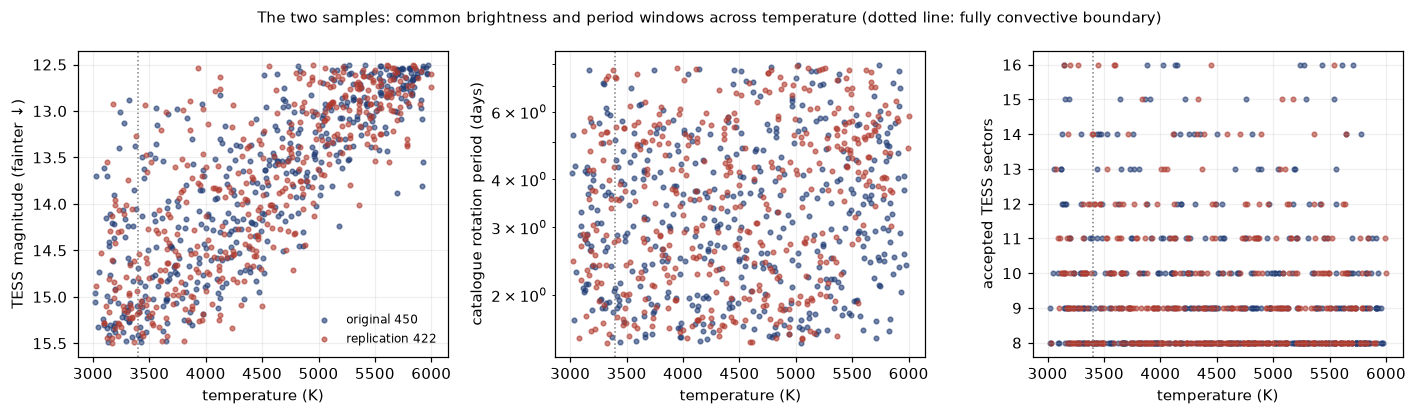

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for df, color, label in [(original, "#1f3b73", "original 450"), (replication, "#b03a2e", "replication 422")]:
    axes[0].scatter(df.teff, df.tmag, s=9, color=color, alpha=0.6, label=label)
    axes[1].scatter(df.teff, df.period, s=9, color=color, alpha=0.6, label=label)
    axes[2].scatter(df.teff, df.sectors, s=9, color=color, alpha=0.6, label=label)
axes[0].set_ylabel("TESS magnitude (fainter ↓)"); axes[0].invert_yaxis()
axes[1].set_ylabel("catalogue rotation period (days)"); axes[1].set_yscale("log")
axes[2].set_ylabel("accepted TESS sectors")
for ax in axes:
    ax.set_xlabel("temperature (K)"); ax.axvline(3400, color="0.5", ls=":", lw=1); ax.grid(alpha=0.2)
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("The two samples: common brightness and period windows across temperature (dotted line: fully convective boundary)", fontsize=10)
fig.tight_layout(); fig.savefig("../figures/01_sample.png", dpi=150)

In [4]:
print("Brightness and period, slice by slice (median):")
summary = original.groupby("teff_bin_low").agg(tmag=("tmag", "median"), period=("period", "median"), sectors=("sectors", "median")).round(2)
summary.index = [f"{int(b)} K" for b in summary.index]
summary.T

Brightness and period, slice by slice (median):


,3000 K,3200 K,3400 K,3600 K,3800 K,4000 K,4200 K,4400 K,4600 K,4800 K,5000 K,5200 K,5400 K,5600 K,5800 K
tmag,14.94,14.76,14.81,14.67,14.54,14.27,14.19,13.84,13.52,13.50,13.25,12.91,12.88,12.72,12.63
period,2.95,2.92,2.96,2.98,3.00,3.08,3.00,3.07,3.07,3.04,3.05,3.22,3.13,3.23,3.90
sectors,10.00,9.00,9.00,9.00,8.00,10.00,9.00,9.00,8.00,9.00,9.00,8.00,8.00,8.50,9.00


**What to notice.** Period and sector count barely change from slice to slice. Brightness does drift: the coolest slices sit near TESS magnitude 14.9, the hottest near 12.6, because M dwarfs are intrinsically dim and the ones bright enough to time are near the faint edge of the window. Fainter means noisier per point, which — if ignored — would make cool stars look *less* steady, not more. It is the reason every star will get its own noise floor in notebook 3 and brightness is a covariate in notebook 4, and it is the direction that makes the result conservative.